# Hierarchical Drift-Diffusion Model (HDDM): Synthetic Parameter Recovery Pipeline

This pipeline demonstrates a complete **Parameter Recovery Analysis** for a Hierarchical Drift-Diffusion Model (HDDM) using PyMC and Bayesian Markov Chain Monte Carlo (MCMC) sampling. 

Parameter recovery is a crucial sanity check in computational psychiatry and decision neuroscience. It ensures that the model architecture can accurately estimate known data-generating parameters ("Ground Truth") from synthetic choice and response time (RT) data.

---

## 🛠 Pipeline Architecture & Overview

### 1. Synthetic Data Generation & Preprocessing
* **Group Means & Inter-Subject Variability:** Defines top-level population distributions for the four classic DDM parameters:
  * **Drift Rate ($v$, Mean = $0.0$, SD = $1.3$):** Information accumulation speed and direction (allows both positive and negative values).
  * **Boundary Separation ($a$, Mean = $2.5$, SD = $0.5$):** Decision threshold / response caution.
  * **Non-Decision Time ($t$, Mean = $0.3$, SD = $0.05$):** Sensorimotor processing & encoding latency.
  * **Starting Point Bias ($z$, Mean = $0.5$, SD = $0.1$):** Initial decision bias toward upper ($z > 0.5$) or lower ($z < 0.5$) boundaries.
* **Hierarchical Sampling:** Generates $N = 50$ synthetic participants with $50$ trials each using `hddm.generate.gen_rand_data`. Individual subject parameters are drawn directly from the group-level distributions.
* **Error Response Flipping:** Uses `hddm.utils.flip_errors(data)` to sign-flip response times corresponding to lower-boundary choices, allowing unified visualization of correct and error RT distributions.

### 2. Parallel MCMC Model Fitting & Diagnostics
* **Parallel Chain Execution:** Uses Python's `multiprocessing.Process` module to execute $2$ independent MCMC chains in parallel on separate CPU cores, drastically reducing runtimes.
* **MCMC Sampling Setup:** Runs $5,000$ iterations per chain with a $500$-iteration burn-in phase.
* **Model Selection via DIC:** Evaluates the Deviance Information Criterion (DIC) across chains and selects the chain with the lowest DIC as the primary reference model.
* **Convergence Diagnostics ($R$-hat / Gelman-Rubin):** Computes Gelman-Rubin ($\hat{R}$) statistics across chains to verify sampling convergence ($\hat{R} < 1.1$).

### 3. Parameter Extraction & Dataset Reconstruction
* Parses parameter traces from HDDM's `nodes_db` for subject-level nodes (`v_subj`, `a_subj`, `t_subj`, `z_subj`).
* Combines individual posterior means into a unified dataset containing both the **True Generated** values and **HDDM Recovered** values.
* Exports the full numerical summary to `parameter_recovery_output/stage_recovered_parameters.csv`.

---

## 📊 Diagnostic Visualizations & Output Artifacts

All visual outputs are rendered at high resolution ($300\text{ DPI}$) and automatically exported to the `parameter_recovery_output/` folder:

1. **Individual Participant RT Distributions (`rt_distributions.png`):**
   * Plots stepped histograms (`subj_data.rt.hist`) showing flipped RT distributions across all 50 participants to visualize inter-subject variability in decision boundaries and errors.

2. **Parameter Density Comparison (`two_stage_parameter_recovery_density.png`):**
   * Overlays Kernel Density Estimation (KDE) plots of True vs. Recovered parameters across $v, a, t, z$.
   * Computes Pearson correlation coefficients ($r$) and exact $p$-values to evaluate distribution alignment.

3. **Scatter Plots with Ideal Identity Reference (`two_stage_parameter_recovery_scatter.png`):**
   * Individual regression plots (`sns.regplot`) comparing participant-level true values against HDDM estimates.
   * Includes a dashed $y = x$ **Ideal Recovery Line** for direct visual assessment of shrinkage or systematic bias.

4. **ArviZ-Style Posterior Overlay & 94% HDI (`arviz_style_direct_plot.png`):**
   * Bayesian posterior diagnostic styling comparing true fitted distributions against recovered values.
   * Annotated population means and horizontal high-density interval bars representing the **94% HDI**.

5. **Comparative Forest Plot (`direct_forest_plot.png`):**
   * Displays population-level means and $95\%$ confidence intervals across all DDM parameters in a clean forest plot format.

---

## 🚀 Key Output Files

| File Path | Description |
| :--- | :--- |
| `parameter_recovery_output/stage_recovered_parameters.csv` | Full CSV table with individual subject ground-truth vs. recovered parameters. |
| `parameter_recovery_output/rt_distributions.png` | Individual participant response time distributions (error-flipped). |
| `parameter_recovery_output/two_stage_parameter_recovery_density.png` | Density comparison (KDE) across parameters. |
| `parameter_recovery_output/two_stage_parameter_recovery_scatter.png` | Scatter plots with regression and $y=x$ identity line. |
| `parameter_recovery_output/arviz_style_direct_plot.png` | Minimalist ArviZ-style posterior KDEs with 94% HDI bars. |
| `parameter_recovery_output/direct_forest_plot.png` | Forest plot comparing true vs. recovered means and 95% CIs. |

Generating hierarchical synthetic data with individual subject differences...
Successfully generated 2500 trials across 50 participants.


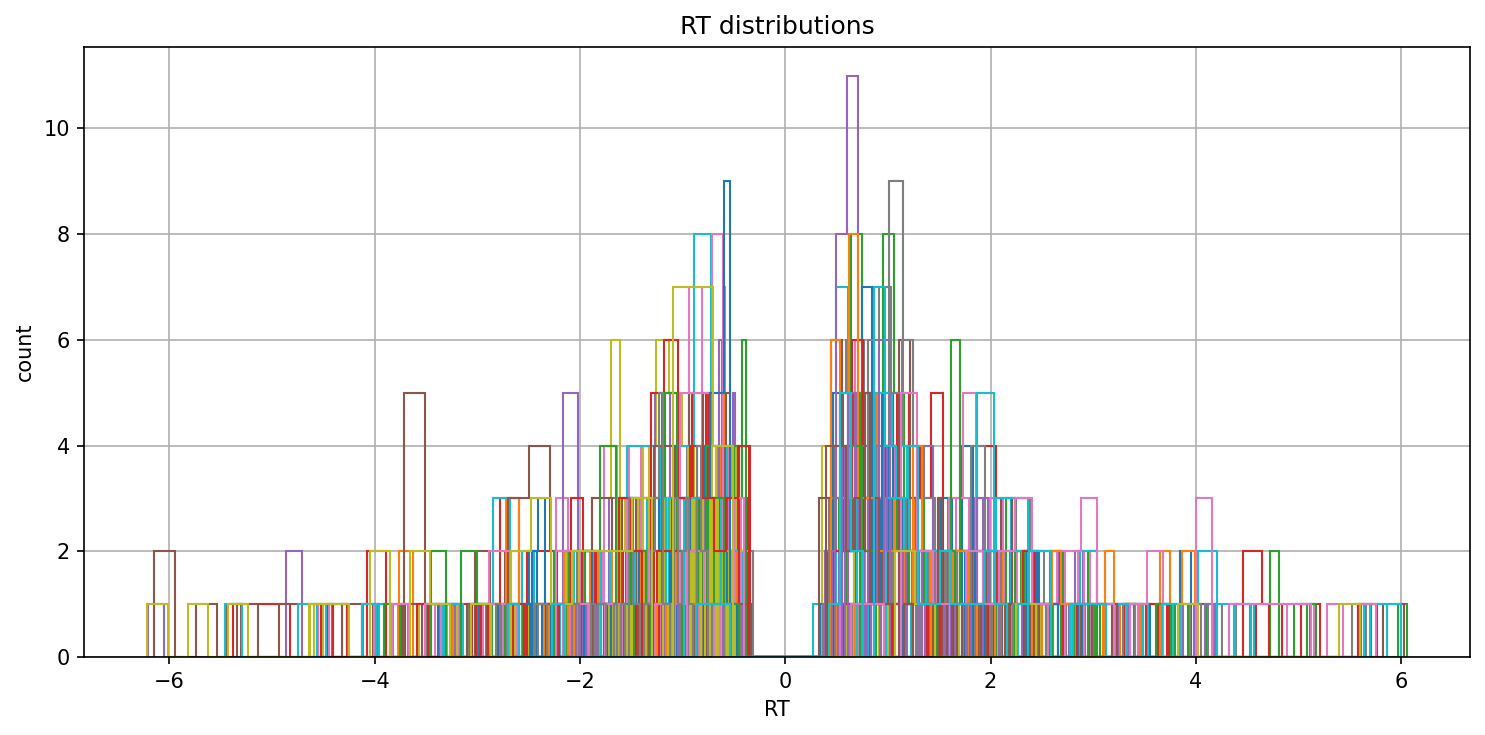


[Parallel MCMC] Launching independent MCMC sampling chains...
Starting Chain 1 on PID 7709...
No model attribute --> setting up standard HDDM
Starting Chain 2 on PID 7712...
No model attribute --> setting up standard HDDM
Set model to ddm
Set model to ddm


/opt/conda/lib/python3.9/site-packages/scipy/optimize/_optimize.py:2309: RuntimeWarning: invalid value encountered in double_scalars
  tmp2 = (x - v) * (fx - fw)
/opt/conda/lib/python3.9/site-packages/scipy/optimize/_optimize.py:2309: RuntimeWarning: invalid value encountered in double_scalars
  tmp2 = (x - v) * (fx - fw)


 [                  0%                  ] 10 of 5000 complete in 0.5 sec[                  0%                  ] 10 of 5000 complete in 0.5 sec[                  0%                  ] 20 of 5000 complete in 1.0 sec[                  0%                  ] 20 of 5000 complete in 1.0 sec[                  0%                  ] 30 of 5000 complete in 1.5 sec[                  0%                  ] 30 of 5000 complete in 1.6 sec[                  0%                  ] 40 of 5000 complete in 2.1 sec[                  0%                  ] 40 of 5000 complete in 2.1 sec[                  1%                  ] 50 of 5000 complete in 2.6 sec[                  1%                  ] 50 of 5000 complete in 2.6 sec[                  1%                  ] 61 of 5000 complete in 3.1 sec[                  1%                  ] 61 of 5000 complete in 3.1 sec[                  1%                  ] 71 of 5000 complete in 3.6 sec[                  1%                  ] 71 of 5000 complete in 3.6 sec[    

 [----             12%                  ] 602 of 5000 complete in 29.9 sec[----             12%                  ] 611 of 5000 complete in 30.4 sec[----             12%                  ] 612 of 5000 complete in 30.4 sec[----             12%                  ] 622 of 5000 complete in 30.9 sec[----             12%                  ] 622 of 5000 complete in 30.9 sec[----             12%                  ] 633 of 5000 complete in 31.4 sec[----             12%                  ] 632 of 5000 complete in 31.5 sec[----             12%                  ] 644 of 5000 complete in 32.0 sec[----             12%                  ] 642 of 5000 complete in 32.0 sec[----             13%                  ] 653 of 5000 complete in 32.5 sec[----             13%                  ] 652 of 5000 complete in 32.6 sec[-----            13%                  ] 663 of 5000 complete in 33.0 sec[-----            13%                  ] 662 of 5000 complete in 33.1 sec[-----            13%                  ] 673 of 50

 [---------        24%                  ] 1208 of 5000 complete in 59.4 sec[---------        24%                  ] 1207 of 5000 complete in 59.8 sec[---------        24%                  ] 1219 of 5000 complete in 59.9 sec[---------        24%                  ] 1218 of 5000 complete in 60.3 sec[---------        24%                  ] 1230 of 5000 complete in 60.5 sec[---------        24%                  ] 1230 of 5000 complete in 60.8 sec[---------        24%                  ] 1241 of 5000 complete in 61.0 sec[---------        24%                  ] 1241 of 5000 complete in 61.4 sec[---------        25%                  ] 1252 of 5000 complete in 61.5 sec[---------        25%                  ] 1251 of 5000 complete in 61.9 sec[---------        25%                  ] 1263 of 5000 complete in 62.0 sec[---------        25%                  ] 1262 of 5000 complete in 62.4 sec[---------        25%                  ] 1274 of 5000 complete in 62.6 sec[---------        25%                

 [-------------    36%                  ] 1830 of 5000 complete in 88.6 sec[-------------    36%                  ] 1806 of 5000 complete in 88.8 sec[-------------    36%                  ] 1840 of 5000 complete in 89.1 sec[-------------    36%                  ] 1817 of 5000 complete in 89.3 sec[--------------   37%                  ] 1850 of 5000 complete in 89.6 sec[-------------    36%                  ] 1828 of 5000 complete in 89.8 sec[--------------   37%                  ] 1861 of 5000 complete in 90.2 sec[-------------    36%                  ] 1839 of 5000 complete in 90.4 sec[--------------   37%                  ] 1872 of 5000 complete in 90.7 sec[--------------   37%                  ] 1850 of 5000 complete in 90.9 sec[--------------   37%                  ] 1883 of 5000 complete in 91.2 sec[--------------   37%                  ] 1862 of 5000 complete in 91.4 sec[--------------   37%                  ] 1893 of 5000 complete in 91.7 sec[--------------   37%                

 [-----------------48%                  ] 2438 of 5000 complete in 117.4 sec[-----------------48%                  ] 2410 of 5000 complete in 117.6 sec[-----------------48%                  ] 2448 of 5000 complete in 117.9 sec[-----------------48%                  ] 2421 of 5000 complete in 118.1 sec[-----------------49%                  ] 2459 of 5000 complete in 118.4 sec[-----------------48%                  ] 2432 of 5000 complete in 118.6 sec[-----------------49%                  ] 2470 of 5000 complete in 118.9 sec[-----------------48%                  ] 2443 of 5000 complete in 119.2 sec[-----------------49%                  ] 2481 of 5000 complete in 119.5 sec[-----------------49%                  ] 2454 of 5000 complete in 119.7 sec[-----------------49%                  ] 2491 of 5000 complete in 120.0 sec[-----------------49%                  ] 2465 of 5000 complete in 120.3 sec[-----------------50%                  ] 2502 of 5000 complete in 120.5 sec[-----------------49%   

 [-----------------60%---               ] 3027 of 5000 complete in 146.3 sec[-----------------60%--                ] 3011 of 5000 complete in 146.4 sec[-----------------60%---               ] 3037 of 5000 complete in 146.8 sec[-----------------60%--                ] 3022 of 5000 complete in 146.9 sec[-----------------60%---               ] 3047 of 5000 complete in 147.3 sec[-----------------60%---               ] 3031 of 5000 complete in 147.4 sec[-----------------61%---               ] 3056 of 5000 complete in 147.8 sec[-----------------60%---               ] 3041 of 5000 complete in 148.0 sec[-----------------61%---               ] 3066 of 5000 complete in 148.4 sec[-----------------61%---               ] 3051 of 5000 complete in 148.5 sec[-----------------61%---               ] 3076 of 5000 complete in 148.9 sec[-----------------61%---               ] 3061 of 5000 complete in 149.0 sec[-----------------61%---               ] 3086 of 5000 complete in 149.4 sec[-----------------61%---

 [-----------------71%-------           ] 3597 of 5000 complete in 175.4 sec[-----------------71%-------           ] 3577 of 5000 complete in 175.4 sec[-----------------72%-------           ] 3607 of 5000 complete in 175.9 sec[-----------------71%-------           ] 3587 of 5000 complete in 175.9 sec[-----------------72%-------           ] 3618 of 5000 complete in 176.4 sec[-----------------71%-------           ] 3598 of 5000 complete in 176.5 sec[-----------------72%-------           ] 3629 of 5000 complete in 176.9 sec[-----------------72%-------           ] 3609 of 5000 complete in 177.0 sec[-----------------72%-------           ] 3640 of 5000 complete in 177.5 sec[-----------------72%-------           ] 3620 of 5000 complete in 177.5 sec[-----------------73%-------           ] 3652 of 5000 complete in 178.0 sec[-----------------72%-------           ] 3631 of 5000 complete in 178.0 sec[-----------------73%-------           ] 3663 of 5000 complete in 178.5 sec[-----------------72%---

 [-----------------83%-----------       ] 4151 of 5000 complete in 204.2 sec[-----------------83%-----------       ] 4178 of 5000 complete in 204.4 sec[-----------------83%-----------       ] 4163 of 5000 complete in 204.7 sec[-----------------83%-----------       ] 4189 of 5000 complete in 205.0 sec[-----------------83%-----------       ] 4175 of 5000 complete in 205.2 sec[-----------------84%-----------       ] 4200 of 5000 complete in 205.5 sec[-----------------83%-----------       ] 4186 of 5000 complete in 205.7 sec[-----------------84%------------      ] 4211 of 5000 complete in 206.1 sec[-----------------83%-----------       ] 4198 of 5000 complete in 206.2 sec[-----------------84%------------      ] 4221 of 5000 complete in 206.6 sec[-----------------84%-----------       ] 4210 of 5000 complete in 206.7 sec[-----------------84%------------      ] 4231 of 5000 complete in 207.1 sec[-----------------84%------------      ] 4223 of 5000 complete in 207.3 sec[-----------------84%---

 [-----------------94%----------------  ] 4743 of 5000 complete in 232.9 sec[-----------------94%---------------   ] 4733 of 5000 complete in 233.2 sec[-----------------95%----------------  ] 4753 of 5000 complete in 233.4 sec[-----------------94%----------------  ] 4743 of 5000 complete in 233.7 sec[-----------------95%----------------  ] 4763 of 5000 complete in 234.0 sec[-----------------95%----------------  ] 4753 of 5000 complete in 234.3 sec[-----------------95%----------------  ] 4770 of 5000 complete in 234.5 sec[-----------------95%----------------  ] 4761 of 5000 complete in 234.8 sec[-----------------95%----------------  ] 4778 of 5000 complete in 235.1 sec[-----------------95%----------------  ] 4769 of 5000 complete in 235.3 sec[-----------------95%----------------  ] 4787 of 5000 complete in 235.6 sec[-----------------95%----------------  ] 4778 of 5000 complete in 235.9 sec[-----------------95%----------------  ] 4796 of 5000 complete in 236.1 sec[-----------------95%---

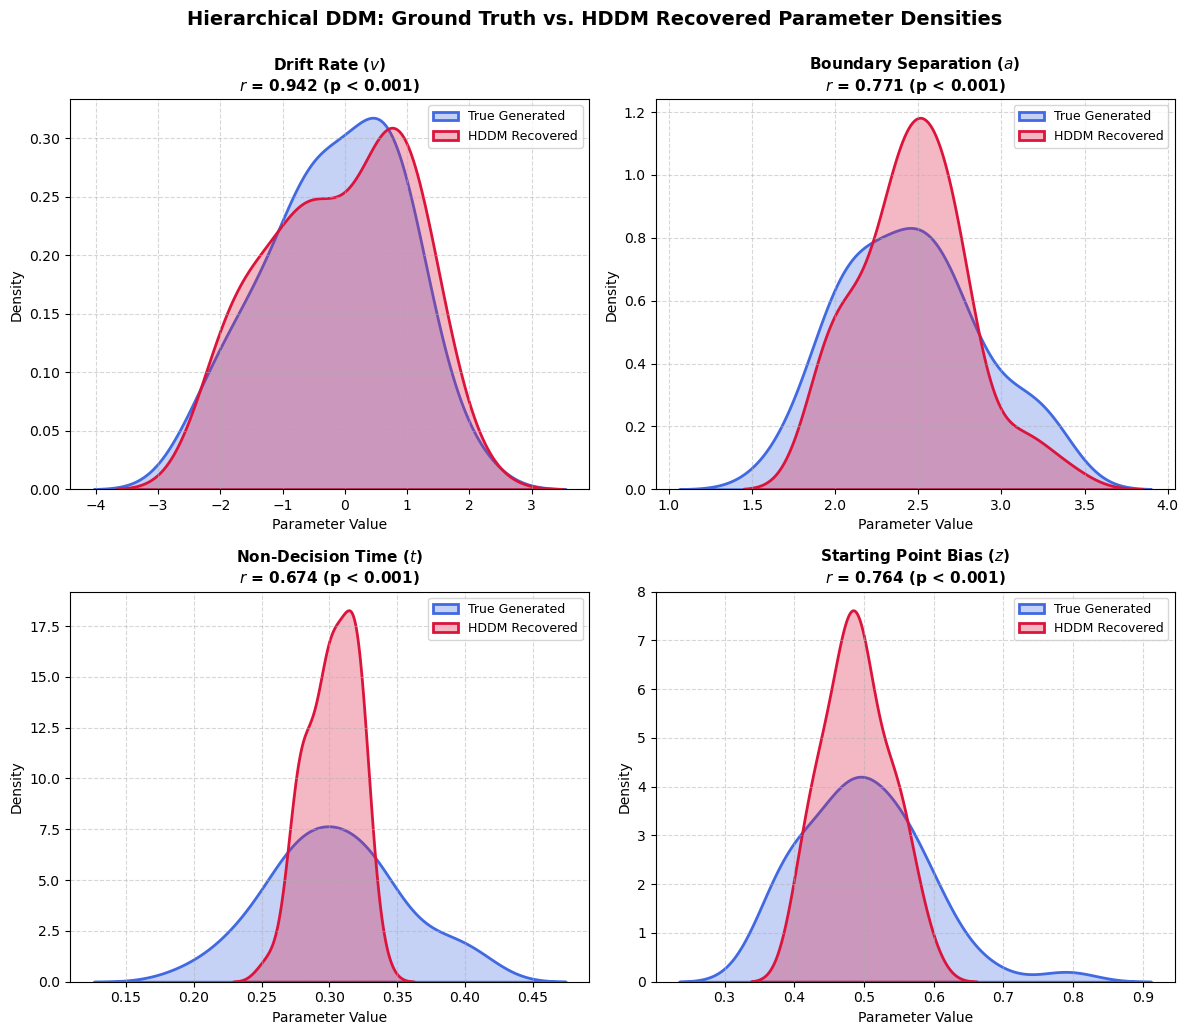

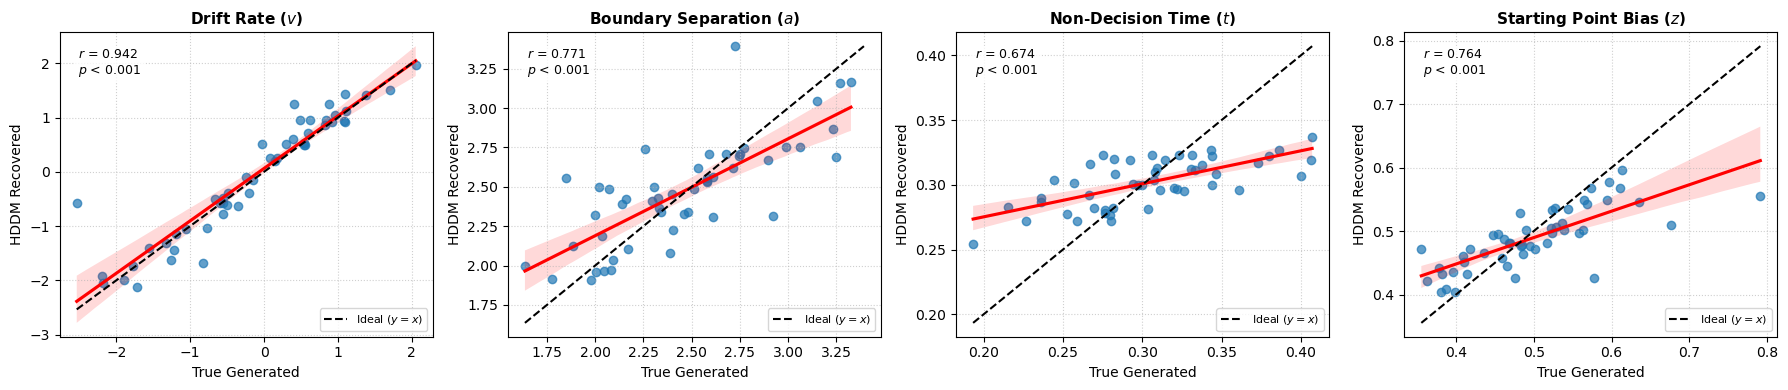

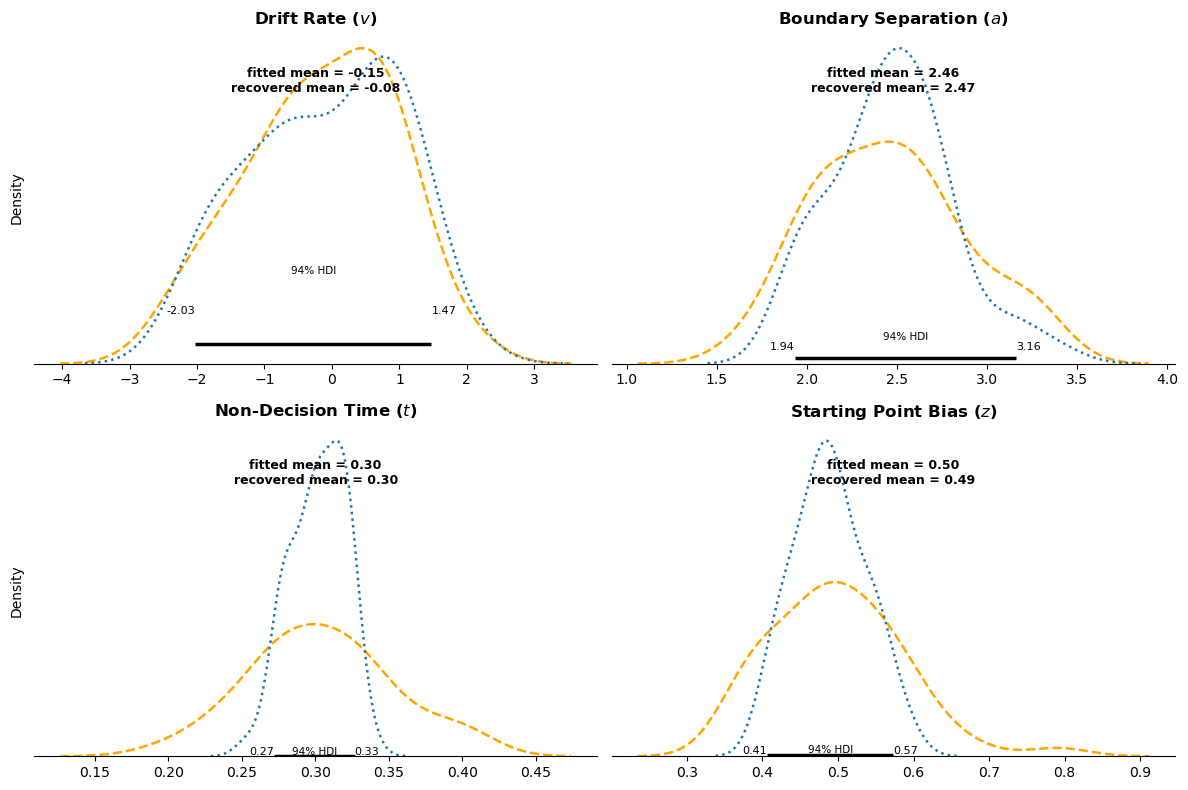

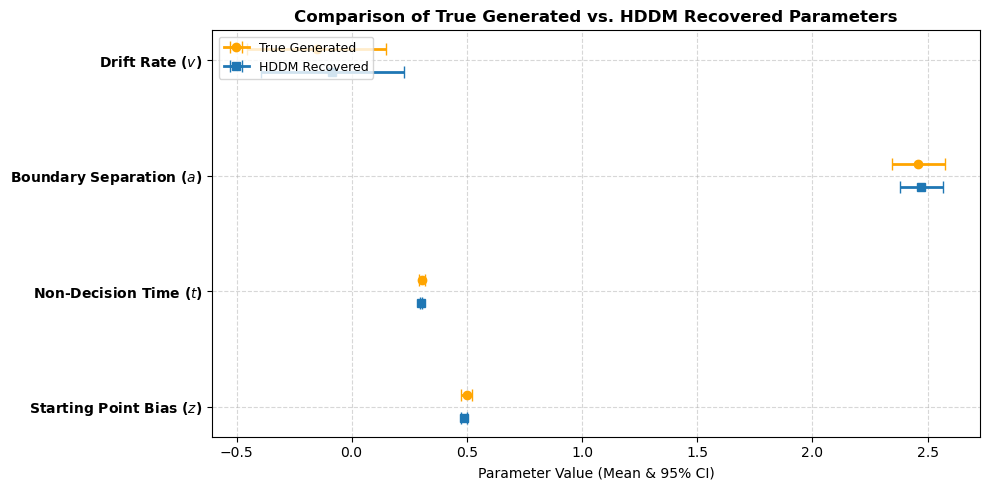


All sampling chains and diagnostic plots successfully completed and saved!


In [3]:
import os
import re
import multiprocessing as mp
import hddm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import seaborn as sns

os.makedirs("parameter_recovery_output", exist_ok=True)

# ============================================================
# 1. SETUP GROUP MEANS & INTER-SUBJECT VARIABILITY (SD)
# ============================================================
group_params = {
    'v': 0.0,   # Group mean drift rate
    'a': 2.5,   # Group mean boundary separation
    't': 0.3,   # Group mean non-decision time
    'z': 0.5    # Group mean starting point bias
}

param_sds = {
    'v': 1.3,
    'a': 0.5,
    't': 0.05,
    'z': 0.1
}

n_subjects = 50
n_trials_per_subject = 50
rng = np.random.default_rng(42)

# ============================================================
# 2. GENERATE HIERARCHICAL SYNTHETIC DATA & GROUND TRUTH
# ============================================================
all_data = []
true_subj_records = []

print("Generating hierarchical synthetic data with individual subject differences...")
for subj_idx in range(n_subjects):
    subj_params = {
        'v': rng.normal(group_params['v'], param_sds['v']),
        'a': max(0.5, rng.normal(group_params['a'], param_sds['a'])),
        't': max(0.05, rng.normal(group_params['t'], param_sds['t'])),
        'z': np.clip(rng.normal(group_params['z'], param_sds['z']), 0.1, 0.9)
    }
    
    true_subj_records.append({
        'subj_idx': subj_idx,
        'v_true': subj_params['v'],
        'a_true': subj_params['a'],
        't_true': subj_params['t'],
        'z_true': subj_params['z']
    })
    
    subj_data, _ = hddm.generate.gen_rand_data(
        params=subj_params, 
        size=n_trials_per_subject, 
        subjs=1
    )
    
    subj_data = subj_data[['rt', 'response']].copy()
    subj_data['subj_idx'] = int(subj_idx)
    all_data.append(subj_data)

ground_truth_df = pd.DataFrame(true_subj_records)
data = pd.concat(all_data, ignore_index=True)
data['subj_idx'] = data['subj_idx'].astype(int)

# Flip RTs for lower boundary responses (errors) for HDDM visualization
data = hddm.utils.flip_errors(data)

print(f"Successfully generated {len(data)} trials across {n_subjects} participants.")

# ============================================================
# PLOT: RT DISTRIBUTIONS ACROSS SUBJECTS
# ============================================================
fig = plt.figure(figsize=(10, 5), dpi=150)
ax = fig.add_subplot(111, xlabel='RT', ylabel='count', title='RT distributions')
for i, subj_data in data.groupby('subj_idx'):
    subj_data.rt.hist(bins=60, histtype='step', ax=ax)

plt.tight_layout()
plt.savefig("parameter_recovery_output/rt_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

# ============================================================
# 3. PARALLEL SAMPLING HELPER FUNCTION
# ============================================================
def run_chain(chain_idx, data_df, queue):
    """Worker function to run a single MCMC chain in parallel."""
    print(f"Starting Chain {chain_idx + 1} on PID {os.getpid()}...")
    model = hddm.HDDM(
        data_df, 
        include=['v', 'a', 't', 'z'],
        informative=True,
        is_group_model=True
    )
    model.find_starting_values()
    model.sample(5000, burn=500, dbname=f'traces_chain_{chain_idx}.db', db='pickle')
    queue.put((chain_idx, model))

if __name__ == '__main__':
    n_chains = 2
    queue = mp.Queue()
    processes = []

    print("\n[Parallel MCMC] Launching independent MCMC sampling chains...")
    for i in range(n_chains):
        p = mp.Process(target=run_chain, args=(i, data, queue))
        processes.append(p)
        p.start()

    models_dict = {}
    for _ in range(n_chains):
        chain_idx, m = queue.get()
        models_dict[chain_idx] = m

    for p in processes:
        p.join()

    models = [models_dict[i] for i in range(n_chains)]

    # ============================================================
    # MODEL SELECTION & DIAGNOSTICS (DIC & GELMAN-RUBIN)
    # ============================================================
    print("\n[Model Selection] Deviance Information Criterion (DIC) for all chains:")
    dic_values = []
    for i, m in enumerate(models):
        dic_val = m.dic
        dic_values.append(dic_val)
        print(f"  • Chain {i+1} DIC: {dic_val:.3f}")

    best_chain_idx = np.argmin(dic_values)
    best_model = models[best_chain_idx]
    print(f"\n=> Selecting Chain {best_chain_idx + 1} as the primary model (Lowest DIC: {dic_values[best_chain_idx]:.3f})")

    print("\n[Convergence Diagnostic] Gelman-Rubin (R-hat) Statistics:")
    gr_stats = hddm.analyze.gelman_rubin(models)
    gr_df = pd.DataFrame.from_dict(gr_stats, orient='index', columns=['R_hat']).sort_values('R_hat', ascending=False)
    print(gr_df.head(20))

    model = best_model
    #best_model.plot_posteriors() #uncomment to plot posteriors and evaluate convergence
    # ============================================================
    # 4. EXTRACT RECOVERED PARTICIPANT PARAMETERS
    # ============================================================
    nodes_db = model.nodes_db.copy()
    nodes_db["node_str"] = nodes_db.index.astype(str)

    rec_v, rec_a, rec_t, rec_z = [], [], [], []
    for subj in range(n_subjects):
        v_val, a_val, t_val, z_val = np.nan, np.nan, np.nan, np.nan
        for idx_name in nodes_db.index:
            name_str = str(idx_name)
            if f".{subj}" in name_str or f"({subj})" in name_str:
                if name_str.startswith("v_subj") or name_str.startswith("v."):
                    v_val = nodes_db.loc[idx_name, "mean"]
                elif name_str.startswith("a_subj") or name_str.startswith("a."):
                    a_val = nodes_db.loc[idx_name, "mean"]
                elif name_str.startswith("t_subj") or name_str.startswith("t."):
                    t_val = nodes_db.loc[idx_name, "mean"]
                elif name_str.startswith("z_subj") or name_str.startswith("z."):
                    z_val = nodes_db.loc[idx_name, "mean"]
        rec_v.append(v_val)
        rec_a.append(a_val)
        rec_t.append(t_val)
        rec_z.append(z_val)

    merged_df = ground_truth_df.copy()
    merged_df["v_rec"] = rec_v
    merged_df["a_rec"] = rec_a
    merged_df["t_rec"] = rec_t
    merged_df["z_rec"] = rec_z

    merged_df.to_csv("parameter_recovery_output/stage_recovered_parameters.csv", index=False)
    print("\nRecovered parameters successfully saved to 'parameter_recovery_output/stage_recovered_parameters.csv'!")

    # ============================================================
    # PLOT 1: DENSITY COMPARISON PLOTS (KDE)
    # ============================================================
    parameters_to_check = [
        ("v_true", "v_rec", "Drift Rate ($v$)"),
        ("a_true", "a_rec", "Boundary Separation ($a$)"),
        ("t_true", "t_rec", "Non-Decision Time ($t$)"),
        ("z_true", "z_rec", "Starting Point Bias ($z$)"),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.flatten()

    for i, (true_col, rec_col, title) in enumerate(parameters_to_check):
        ax = axes[i]
        sub_df = merged_df[[true_col, rec_col]].apply(pd.to_numeric, errors="coerce").dropna()

        sns.kdeplot(data=sub_df[true_col], ax=ax, color="royalblue", fill=True, alpha=0.3, linewidth=2, label="True Generated")
        sns.kdeplot(data=sub_df[rec_col], ax=ax, color="crimson", fill=True, alpha=0.3, linewidth=2, label="HDDM Recovered")

        r, p_val = pearsonr(sub_df[true_col], sub_df[rec_col])
        p_str = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"

        ax.set_title(f"{title}\n$r$ = {r:.3f} ({p_str})", fontsize=11, fontweight="bold")
        ax.set_xlabel("Parameter Value")
        ax.set_ylabel("Density")
        ax.legend(loc="upper right", fontsize=9)
        ax.grid(True, linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.suptitle("Hierarchical DDM: Ground Truth vs. HDDM Recovered Parameter Densities", y=1.03, fontsize=14, weight="bold")
    plt.savefig("parameter_recovery_output/two_stage_parameter_recovery_density.png", dpi=300, bbox_inches="tight")
    plt.show()

    # ============================================================
    # PLOT 2: INDIVIDUAL REGRESSION & SCATTER WITH IDENTITY LINES (y = x)
    # ============================================================
    def regplot_with_corr(x, y, ax, title):
        sub_df = pd.DataFrame({'x': x, 'y': y}).dropna()
        if len(sub_df) < 2:
            ax.text(0.5, 0.5, "Insufficient data", ha='center', va='center')
            return
        r, p_val = pearsonr(sub_df['x'], sub_df['y'])
        p_str = "$p$ < 0.001" if p_val < 0.001 else f"$p$ = {p_val:.3f}"
        
        sns.regplot(data=sub_df, x='x', y='y', ax=ax, scatter_kws={'alpha': 0.7, 'color': '#1f77b4'}, line_kws={'color': 'red'})
        
        min_val = min(sub_df['x'].min(), sub_df['y'].min())
        max_val = max(sub_df['x'].max(), sub_df['y'].max())
        ax.plot([min_val, max_val], [min_val, max_val], 'k--', lw=1.5, label='Ideal ($y=x$)')
        
        text = f"$r$ = {r:.3f}\n{p_str}"
        ax.text(0.05, 0.95, text, transform=ax.transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8, edgecolor='none'), fontsize=9)
        ax.set_title(title, fontsize=11, fontweight='bold')
        ax.set_xlabel("True Generated")
        ax.set_ylabel("HDDM Recovered")
        ax.legend(loc='lower right', fontsize=8)
        ax.grid(True, linestyle=':', alpha=0.6)

    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    for i, (true_col, rec_col, title) in enumerate(parameters_to_check):
        sub_df = merged_df[[true_col, rec_col]].dropna()
        regplot_with_corr(x=sub_df[true_col], y=sub_df[rec_col], ax=axes[i], title=title)

    plt.tight_layout()
    plt.savefig("parameter_recovery_output/two_stage_parameter_recovery_scatter.png", dpi=300, bbox_inches='tight')
    plt.show()

    # ============================================================
    # PLOT 3: ARVIZ-STYLE OVERLAY WITH 94% HDI
    # ============================================================
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes = axes.flatten()

    for i, (true_col, rec_col, title) in enumerate(parameters_to_check):
        ax = axes[i]
        sub_df = merged_df[[true_col, rec_col]].apply(pd.to_numeric, errors='coerce').dropna()
        
        vals_true = sub_df[true_col].values
        vals_rec = sub_df[rec_col].values
        
        mean_true = np.mean(vals_true)
        mean_rec = np.mean(vals_rec)
        hdi_rec = np.percentile(vals_rec, [3, 97])
        
        sns.kdeplot(x=vals_true, ax=ax, color="orange", linestyle="dashed", label="fitted", lw=1.8)
        sns.kdeplot(x=vals_rec, ax=ax, color="tab:blue", linestyle="dotted", label="recovered", lw=1.8)
        
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)
        ax.set_yticks([])
        ax.set_ylabel('Density' if i % 2 == 0 else '', fontsize=10)
        ax.set_title(title, fontsize=12, fontweight='bold')
        
        ax.text(0.5, 0.82, f"fitted mean = {mean_true:.2f}\nrecovered mean = {mean_rec:.2f}", 
                transform=ax.transAxes, ha='center', fontsize=9, fontweight='bold')
        
        ax.hlines(y=0.02, xmin=hdi_rec[0], xmax=hdi_rec[1], color='black', linewidth=2.5)
        ax.text(hdi_rec[0], 0.05, f"{hdi_rec[0]:.2f}", ha='right', fontsize=8)
        ax.text(hdi_rec[1], 0.05, f"{hdi_rec[1]:.2f}", ha='left', fontsize=8)
        ax.text(np.mean(hdi_rec), 0.09, "94% HDI", ha='center', fontsize=7.5)

    plt.tight_layout()
    plt.savefig("parameter_recovery_output/arviz_style_direct_plot.png", dpi=300, bbox_inches='tight')
    plt.show()

    # ============================================================
    # PLOT 4: FOREST PLOT COMPARATIVE (MEANS & 95% CI)
    # ============================================================
    fig, ax = plt.subplots(figsize=(10, 5))

    y_ticks = np.arange(len(parameters_to_check))
    labels = [p[2] for p in parameters_to_check]

    for idx, (true_col, rec_col, title) in enumerate(parameters_to_check):
        sub_df = merged_df[[true_col, rec_col]].apply(pd.to_numeric, errors='coerce').dropna()
        
        true_mean = sub_df[true_col].mean()
        true_ci = 1.96 * sub_df[true_col].sem()
        
        rec_mean = sub_df[rec_col].mean()
        rec_ci = 1.96 * sub_df[rec_col].sem()
        
        ax.errorbar(true_mean, idx - 0.1, xerr=true_ci, fmt='o-', color='orange', label='True Generated' if idx == 0 else "", capsize=4, lw=2)
        ax.errorbar(rec_mean, idx + 0.1, xerr=rec_ci, fmt='s-', color='tab:blue', label='HDDM Recovered' if idx == 0 else "", capsize=4, lw=2)

    ax.set_yticks(y_ticks)
    ax.set_yticklabels(labels, fontweight='bold')
    ax.invert_yaxis()
    ax.set_xlabel("Parameter Value (Mean & 95% CI)")
    ax.set_title("Comparison of True Generated vs. HDDM Recovered Parameters", fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig("parameter_recovery_output/direct_forest_plot.png", dpi=300, bbox_inches='tight')
    plt.show()

    print("\nAll sampling chains and diagnostic plots successfully completed and saved!")